##Salary prediction with polynomial linear regression

---



---



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv('/content/Salary_Data.csv')
df

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
...,...,...,...,...,...,...
6699,49.0,Female,PhD,Director of Marketing,20.0,200000.0
6700,32.0,Male,High School,Sales Associate,3.0,50000.0
6701,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0
6702,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0


In [ ]:
df.shape


(6704, 6)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [ ]:
df.isnull().sum()

,0
Age,2
Gender,2
Education Level,3
Job Title,2
Years of Experience,3
Salary,5


In [ ]:
df.dropna(inplace=True)
df.isnull().sum()
print(df)

       Age  Gender    Education Level              Job Title  \
0     32.0    Male         Bachelor's      Software Engineer   
1     28.0  Female           Master's           Data Analyst   
2     45.0    Male                PhD         Senior Manager   
3     36.0  Female         Bachelor's        Sales Associate   
4     52.0    Male           Master's               Director   
...    ...     ...                ...                    ...   
6699  49.0  Female                PhD  Director of Marketing   
6700  32.0    Male        High School        Sales Associate   
6701  30.0  Female  Bachelor's Degree      Financial Manager   
6702  46.0    Male    Master's Degree      Marketing Manager   
6703  26.0  Female        High School        Sales Executive   

      Years of Experience    Salary  
0                     5.0   90000.0  
1                     3.0   65000.0  
2                    15.0  150000.0  
3                     7.0   60000.0  
4                    20.0  200000.0  
...

In [ ]:
x = df.iloc[:,4:5]
x

,Years of Experience
0,5.0
1,3.0
2,15.0
3,7.0
4,20.0
...,...
6699,20.0
6700,3.0
6701,4.0
6702,14.0


In [ ]:
y = df.iloc[:,-1]
y

,Salary
0,90000.0
1,65000.0
2,150000.0
3,60000.0
4,200000.0
...,...
6699,200000.0
6700,50000.0
6701,55000.0
6702,140000.0


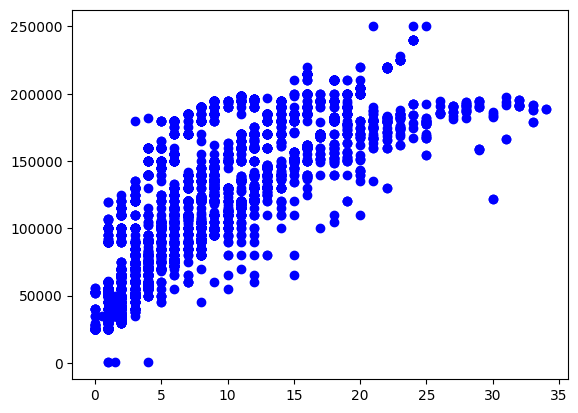

In [ ]:
plt.scatter(x, y, color='blue')

<Axes: xlabel='Years of Experience', ylabel='Salary'>

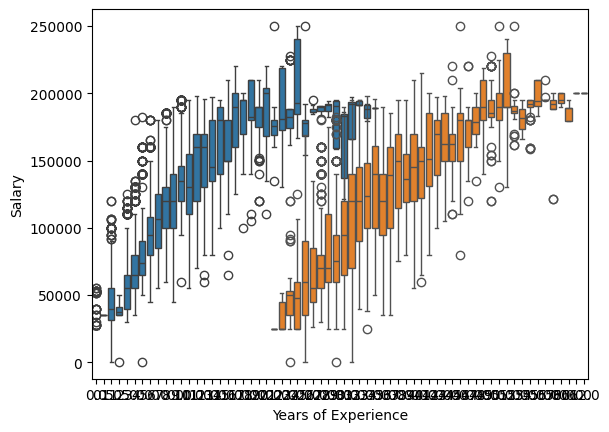

In [ ]:
sns.boxplot(x='Years of Experience',y='Salary',data=df)
sns.boxplot(x='Age',y='Salary',data=df)

In [ ]:
q3 = df['Salary'].quantile(0.75)
q1 = df['Salary'].quantile(0.25)
IQR = q3 - q1
print(IQR)

90000.0


In [ ]:
#ul = q3 + 1.5*IQR
#ll = q1 - 1.5*IQR
#upper = np.where(df['Salary']>=ul)
#lower = np.where(df['Salary']<=ll)
#df.drop(upper[0],axis=0,inplace=True)
#df.drop(lower[0],axis=0,inplace=True)
#plr.prr

In [ ]:
x1= df.iloc[:,0:1]
x1

,Age
0,32.0
1,28.0
2,45.0
3,36.0
4,52.0
...,...
6699,49.0
6700,32.0
6701,30.0
6702,46.0


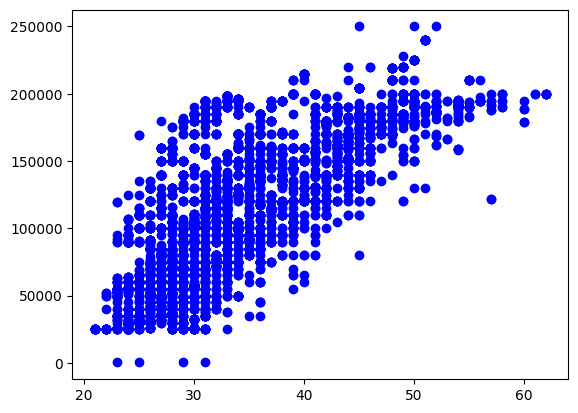

In [ ]:
plt.scatter(x1, y, color='blue')

In [ ]:
x_ = df.iloc[:,[0,4]]
x_

,Age,Years of Experience
0,32.0,5.0
1,28.0,3.0
2,45.0,15.0
3,36.0,7.0
4,52.0,20.0
...,...,...
6699,49.0,20.0
6700,32.0,3.0
6701,30.0,4.0
6702,46.0,14.0


In [ ]:
from sklearn.linear_model import LinearRegression
slr = LinearRegression()
slr.fit(x_,x1,y)
slr.fit(x,y)
slr.fit(x1,y)
slr.fit(x_,y)

LinearRegression()

In [ ]:
y_pred = slr.predict(x_)
y_pred

array([ 89968.27708896,  78756.4039208 , 158303.3489757 , ...,
        84362.34050488, 147436.3955148 ,  64037.18616808])

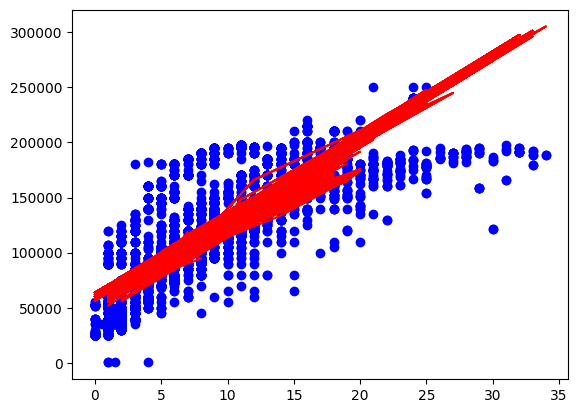

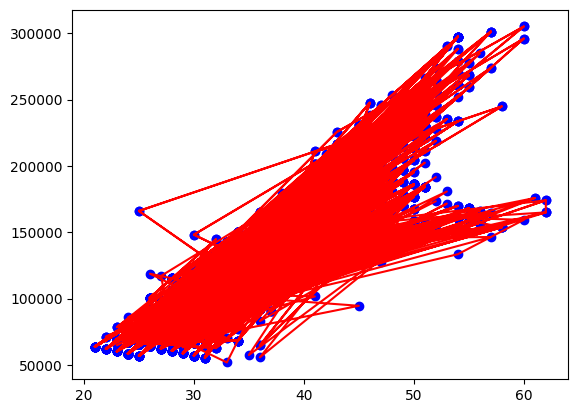

In [ ]:
plt.scatter(x, y, color='blue')
plt.plot(x, y_pred, color='red')
plt.show()
plt.scatter(x1, y_pred, color='blue')
plt.plot(x1, y_pred, color='red')
plt.show()

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
pl = PolynomialFeatures(degree=4)
x_pl = pl.fit_transform(x_)

In [ ]:
plr = LinearRegression()
plr.fit(x_pl,y)

LinearRegression()

In [ ]:
y_prl=plr.predict(x_pl)

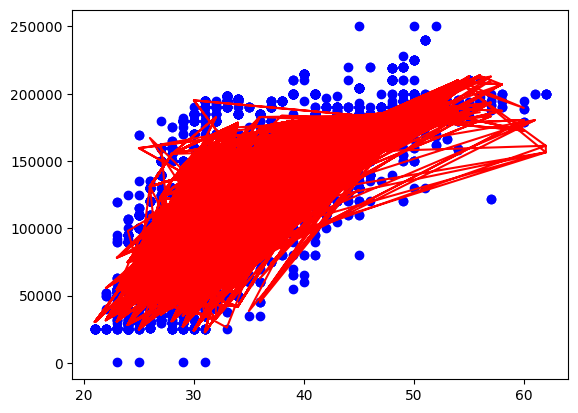

In [ ]:
plt.scatter(x1,y,color='blue')
plt.plot(x1,y_prl,color='red')
plt.show()

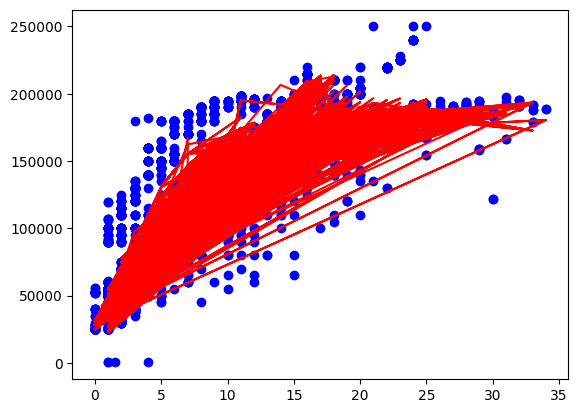

In [ ]:
plt.scatter(x,y,color='blue')
plt.plot(x,y_prl,color='red')
plt.show()

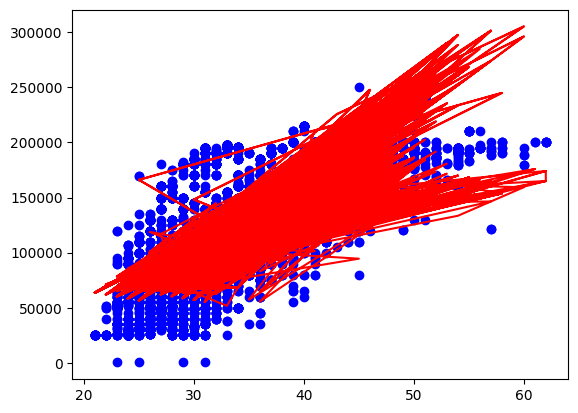

*******************************************NEXT******************************************


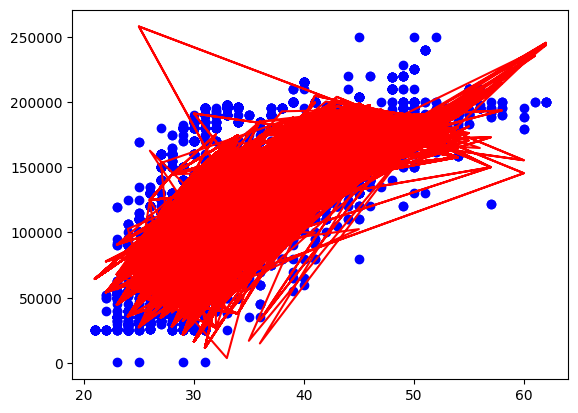

*******************************************NEXT******************************************


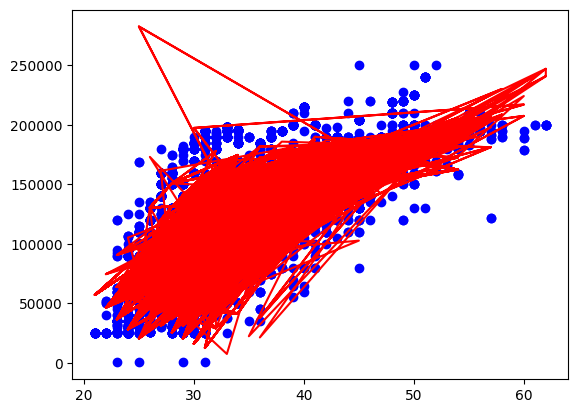

*******************************************NEXT******************************************


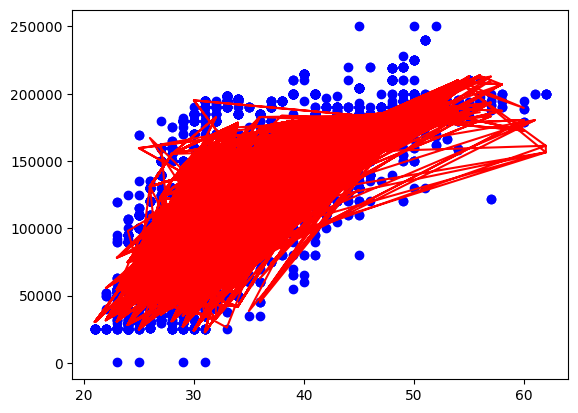

*******************************************NEXT******************************************


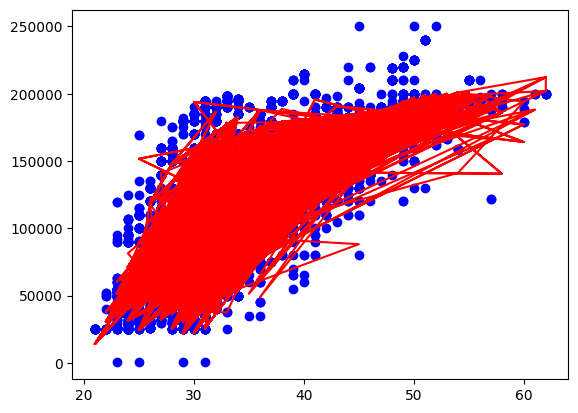

*******************************************NEXT******************************************


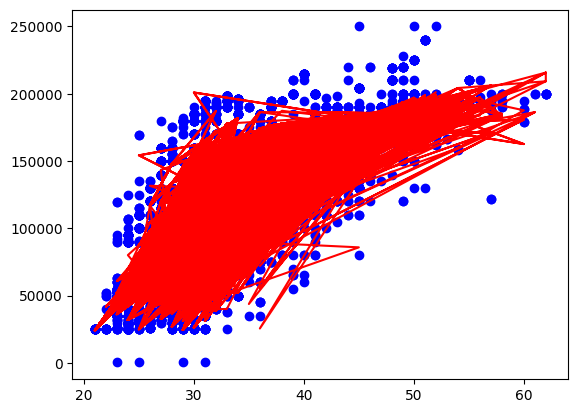

*******************************************NEXT******************************************


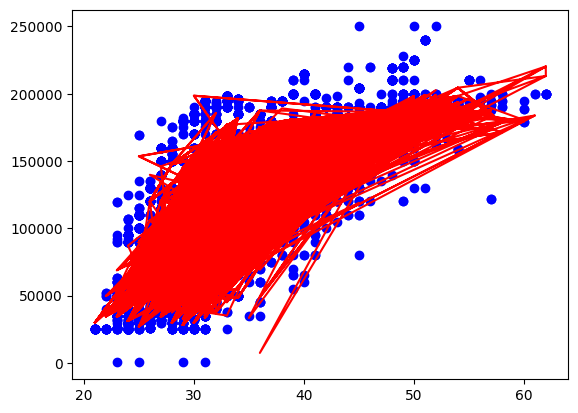

*******************************************NEXT******************************************


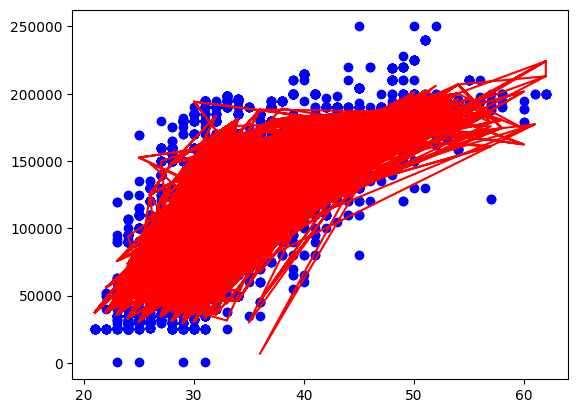

*******************************************NEXT******************************************


In [ ]:
for i in range(1,9):
  pl = PolynomialFeatures(degree=i)
  x_pl = pl.fit_transform(x_)
  plr = LinearRegression()
  plr.fit(x_pl,y)
  y_prl=plr.predict(x_pl)
  plt.scatter(x1,y,color='blue')
  plt.plot(x1,y_prl,color='red')
  plt.show()
  print('*******************************************NEXT******************************************')

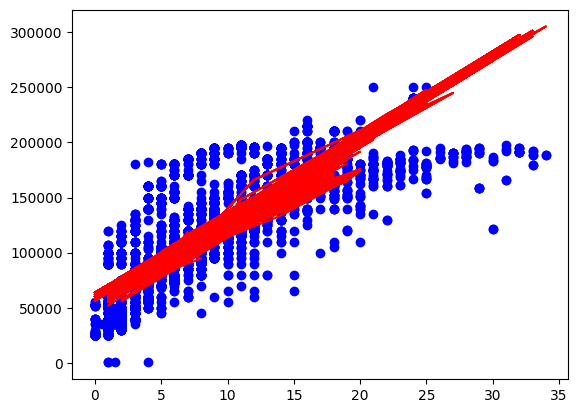

*******************************************NEXT******************************************


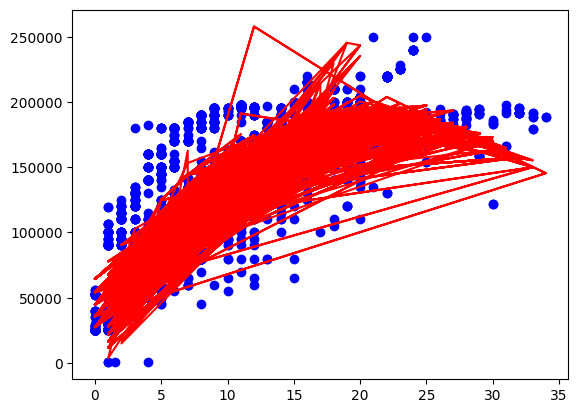

*******************************************NEXT******************************************


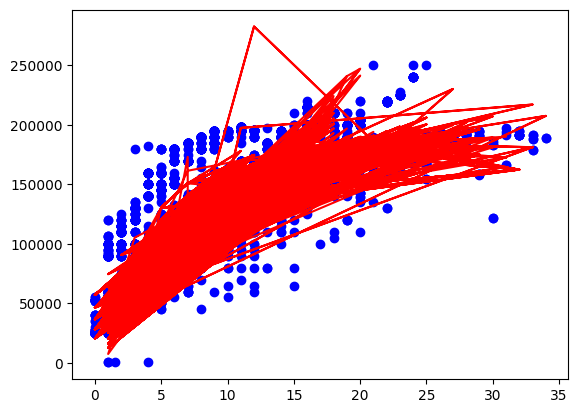

*******************************************NEXT******************************************


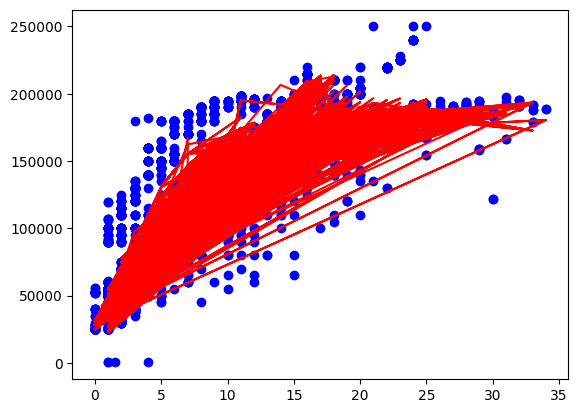

*******************************************NEXT******************************************


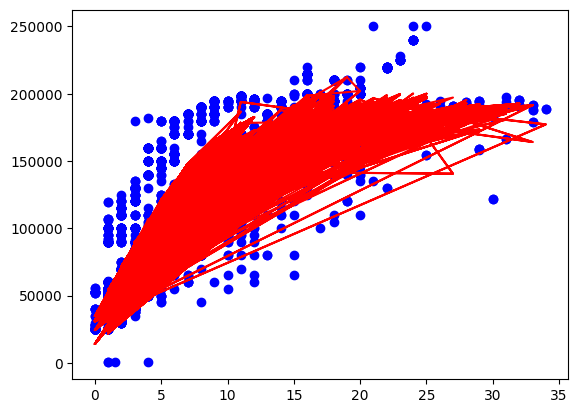

*******************************************NEXT******************************************


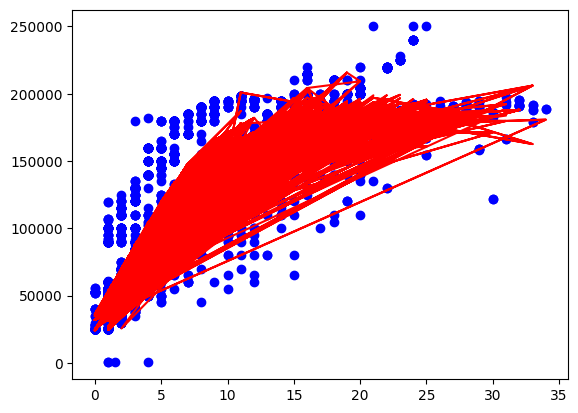

*******************************************NEXT******************************************


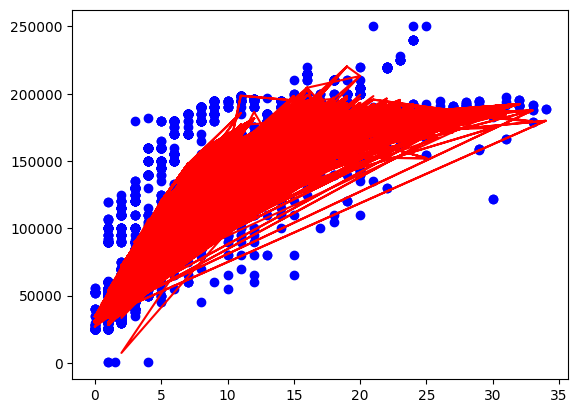

*******************************************NEXT******************************************


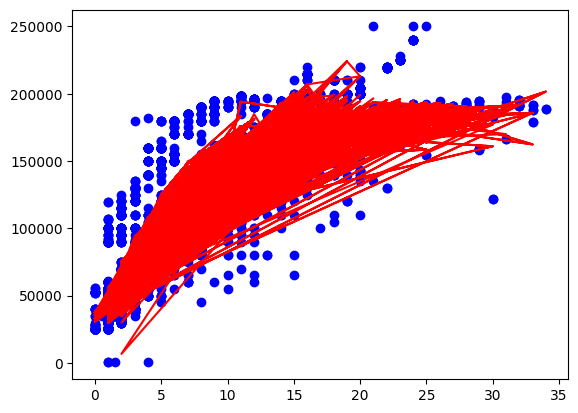

*******************************************NEXT******************************************


In [ ]:
for i in range(1,9):
  pl = PolynomialFeatures(degree=i)
  x_pl = pl.fit_transform(x_)
  plr = LinearRegression()
  plr.fit(x_pl,y)
  y_prl=plr.predict(x_pl)
  plt.scatter(x,y,color='blue')
  plt.plot(x,y_prl,color='red')
  plt.show()
  print('*******************************************NEXT******************************************')

In [ ]:
pl = PolynomialFeatures(degree=7)
x_pl = pl.fit_transform(x_)
plr.fit(x_pl,y)

LinearRegression()

In [ ]:
from sklearn.metrics import r2_score
r2_score(plr.predict(x_pl),y)

0.752687511335526

In [ ]:
plr.predict(pl.fit_transform([[73,19]]))

array([786298.6428448])

In [ ]:
plr.predict(pl.fit_transform([[73,19],[18,2],[32,6]]))

array([786298.64285239, -59523.31456061,  98898.21068307])